In [1]:
import numpy as np
from scipy.sparse.linalg import svds
import fastplotlib as fpl
from matplotlib import pyplot as plt
import seaborn as sns
from tqdm import tqdm
from itertools import product
from typing import *

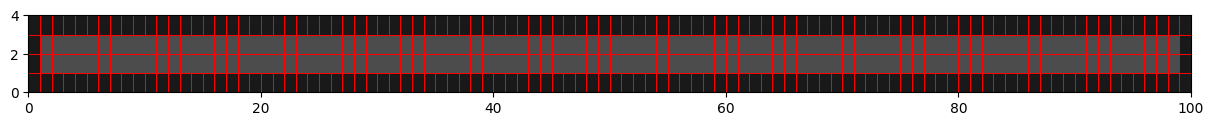

In [2]:
nrows = 4
ncols = 100

shape = (nrows, ncols)

a = np.ones(shape, dtype=np.float32)

mask = (slice(1, -1), slice(1, -1))

baseline_value = 3

a[mask] = baseline_value

fig = plt.figure(figsize=(15, 1))
plt.pcolormesh(a, edgecolors="r", linewidth=0.5, cmap="gray", vmin=0, vmax=10)

In [4]:
prop_length = a[mask].shape[1]

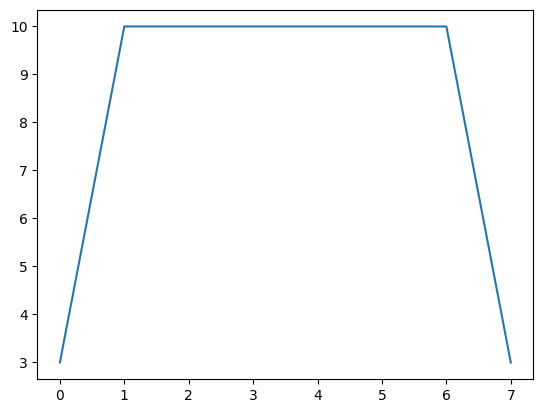

In [29]:
wave = np.array([0.3, 1, 1, 1, 1, 1, 1, 0.3]) * 10
plt.plot(wave)

In [30]:
wave.shape

(8,)

In [31]:
n_frames = prop_length + wave.size

pseudo_length = prop_length + wave.size
movie = np.zeros((pseudo_length, a.shape[0], a.shape[1]))

for i in range(0, pseudo_length):
    movie[i] = a.copy()
    
    movie[i][mask] = np.pad(wave, (i, prop_length - i + wave.size), mode="constant", constant_values=baseline_value)[wave.size:-wave.size]

In [32]:
iw = fpl.ImageWidget(movie)
iw.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…